# Semana 12 · Taller guiado · SOLUCIONARIO
# Contar para ver el sesgo: Python desde cero

**Principios de Inteligencia Artificial · 2026-B · Corte 3**

En la sesión de contenido vimos que un modelo puede tener una exactitud general alta y, aun así, equivocarse **mucho más con un grupo de personas que con otro**. La forma de descubrirlo es sencilla: **contar los errores por grupo** y comparar los porcentajes.

En este cuaderno usted va a hacer esa cuenta con **Python**, desde cero. No necesita saber programar: cada paso explica una sola instrucción nueva y la usa enseguida.

| Parte | Qué trae |
|---|---|
| **A** | Lo mínimo de Python: variables, listas, sumar, contar y porcentajes |
| **B** | Los datos: 24 solicitudes de crédito y la exactitud general |
| **C** | La prueba del auditor: contar los errores por grupo con `for` e `if` |
| **D** | La gráfica y la pregunta de fondo: ¿de dónde viene el sesgo? |
| **E** | **Taller para entregar** (individual, 5 puntos) |

### Cómo usar este cuaderno

1. Lea el texto de cada paso.
2. Haga clic en la celda gris de código que viene debajo y presione el botón ▶ (o `Shift + Enter`).
3. Mire lo que aparece debajo de la celda y compárelo con la explicación.

Las celdas se ejecutan **en orden, de arriba abajo**. Si algo se daña, use el menú **Entorno de ejecución → Reiniciar y ejecutar todo** y el cuaderno vuelve a quedar como estaba.

Cuando haya un número que usted puede cambiar, estará marcado con **⬅️ CAMBIE ESTE NÚMERO**.

> **Este es el solucionario.** Las partes A a D son las mismas del cuaderno del taller. La parte E está resuelta paso a paso: primero la cuenta a mano, después el código y al final la explicación.

---
# PARTE A · Lo mínimo de Python

## Paso 1 · Python como calculadora

Lo primero que hace Python es lo mismo que una calculadora. Escriba una cuenta, ejecútela y Python muestra el resultado.

- `+` suma, `-` resta, `*` multiplica y `/` divide.
- `print(...)` muestra en pantalla lo que va dentro del paréntesis.

Ejecute la celda.

In [ ]:
print(5 + 3)
print(10 - 4)
print(6 * 7)
print(25 / 256)

8
6
42
0.25


La última línea dio **0.3**. Python usa **punto** para los decimales, no coma. Ese 0.3 es el mismo **15 ÷ 50** del ejemplo trabajado de la sesión: 15 personas negadas de 50 buenos pagadores. En porcentaje, 0.3 es el **30 %**.

> Para pasar un número a porcentaje se multiplica por 100: 0.3 × 100 = 30 %.

## Paso 2 · Variables: ponerle nombre a un número

Una **variable** es una caja con nombre donde se guarda un valor. Se crea con el signo `=`:

```python
buenos_pagadores = 50
```

Se lee así: «guarde 50 en la caja que se llama `buenos_pagadores`». Después se puede usar el nombre en lugar del número, y la cuenta se entiende mucho mejor.

Reglas de los nombres: sin espacios (se usa `_` en su lugar), sin tildes y sin empezar por un número.

In [3]:
buenos_pagadores = 50
negados = 15

porcentaje_negado = negados / buenos_pagadores * 100
print("Porcentaje negado injustamente:", porcentaje_negado, "%")

Porcentaje negado injustamente: 30.0 %


Fíjese en que `print` puede mostrar varias cosas separadas por comas: un texto entre comillas, el valor de una variable y otro texto.

Ahora cambie el `15` por un `5` (es el grupo A del ejemplo de la sesión) y vuelva a ejecutar la celda. Debe salir **10.0 %**.

## Paso 3 · Listas: varios valores en una sola variable

Cuando hay muchos datos del mismo tipo se guardan en una **lista**: los valores van entre corchetes `[ ]` y separados por comas.

Tres instrucciones que sirven para casi todo:

| Instrucción | Qué hace |
|---|---|
| `len(lista)` | cuenta cuántos elementos tiene |
| `sum(lista)` | suma todos los elementos |
| `sum(lista) / len(lista)` | el **promedio** |

Ejecute la celda con las notas de un estudiante.

In [4]:
notas = [3.5, 4.0, 2.8, 4.6, 3.1]

print("Cantidad de notas:", len(notas))
print("Suma de las notas:", sum(notas))
print("Promedio:", sum(notas) / len(notas))

Cantidad de notas: 5
Suma de las notas: 18.0
Promedio: 3.6


Haga la cuenta a mano para comprobar: 3,5 + 4,0 + 2,8 + 4,6 + 3,1 = **18,0**, y 18,0 ÷ 5 = **3,6**. Python dice lo mismo. A veces muestra algo como `3.5999999999999996`; es un detalle de cómo el computador guarda los decimales, y se arregla redondeando con `round(numero, 1)`.

## Paso 4 · `if`: tomar una decisión

`if` significa «si». Le permite al programa hacer algo **solo cuando se cumple una condición**.

```python
if nota >= 3.0:
    print("Pasó")
else:
    print("Perdió")
```

- `>=` significa «mayor o igual», `<` «menor», `==` «igual» (con **dos** signos: uno solo es para guardar en una variable).
- La línea del `if` termina en **dos puntos** `:`.
- Lo que va dentro del `if` se escribe **corrido hacia la derecha** (con 4 espacios). Python usa esa sangría para saber qué está dentro y qué no.

In [5]:
nota = 2.99   # ⬅️ CAMBIE ESTE NÚMERO y vuelva a ejecutar

if nota >= 3.0:
    print(nota, "→ Pasó")
else:
    print(nota, "→ Perdió")

2.99 → Perdió


Es el mismo umbral de la semana 11: con 2,99 pierde y con 3,0 pasa. Pruebe con 3.0 y con 4.5.

## Paso 5 · `for`: repetir para cada elemento

`for` recorre una lista **elemento por elemento** y hace lo mismo con cada uno. Se lee: «para cada `nota` de la lista `notas`, haga…».

Si se combina con un **contador** (una variable que arranca en 0 y va sumando 1), se puede **contar cuántos elementos cumplen una condición**. Ese es el truco de todo el taller.

In [6]:
notas = [3.5, 4.0, 2.8, 4.6, 3.1, 2.5, 3.0]

perdidas = 0                      # el contador arranca en cero
for nota in notas:
    if nota < 3.0:
        perdidas = perdidas + 1   # encontró una perdida: sume 1
        print(nota, "→ perdida")

print("Materias perdidas:", perdidas, "de", len(notas))
print("Porcentaje perdido:", round(perdidas / len(notas) * 100, 1), "%")

2.8 → perdida
2.5 → perdida
Materias perdidas: 2 de 7
Porcentaje perdido: 28.6 %


Recorra la lista con el dedo: 2,8 y 2,5 son menores que 3,0. Son **2 de 7**, y 2 ÷ 7 × 100 = **28,6 %**. Con estas cinco ideas (variables, listas, `if`, `for` y el contador) ya puede hacer el trabajo de un auditor de IA.

---
# PARTE B · Los datos

## Paso 6 · Las 24 solicitudes de crédito

Un banco usa un modelo de IA para aprobar o negar créditos. Lo probamos con **24 personas inventadas**: 12 del **grupo A** y 12 del **grupo B**.

De cada persona sabemos tres cosas, cada una en su propia lista (la posición 1 de cada lista es la misma persona, la posición 2 es otra persona, y así):

- `grupo`: si es del grupo A o del grupo B.
- `pagaria`: si de verdad habría pagado el crédito (`"sí"` o `"no"`).
- `decision`: lo que decidió el modelo (`"aprobado"` o `"negado"`).

Ejecute la celda: crea las listas y las muestra como una tabla para que se lean mejor.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

grupo = ["A"] * 12 + ["B"] * 12

pagaria = ["sí"] * 10 + ["no"] * 2 + ["sí"] * 10 + ["no"] * 2

decision = (["aprobado"] * 9 + ["negado"] + ["negado"] * 2      # grupo A
            + ["aprobado"] * 7 + ["negado"] * 3 + ["negado"] * 2)  # grupo B

tabla = pd.DataFrame({"persona": range(1, 25), "grupo": grupo,
                      "pagaría": pagaria, "decisión del modelo": decision})
tabla

,persona,grupo,pagaría,decisión del modelo
0,1,A,sí,aprobado
1,2,A,sí,aprobado
2,3,A,sí,aprobado
3,4,A,sí,aprobado
4,5,A,sí,aprobado
5,6,A,sí,aprobado
6,7,A,sí,aprobado
7,8,A,sí,aprobado
8,9,A,sí,aprobado
9,10,A,sí,negado


La tabla es pequeña a propósito: **usted puede contar con el dedo** y comprobar cada cosa que calcule Python. En la vida real son miles de filas y ahí sí no queda otra que contar con código, pero la cuenta es exactamente la misma.

## Paso 7 · `zip`: recorrer las tres listas a la vez

Para revisar a cada persona hay que mirar sus tres datos juntos. `zip` toma varias listas y las recorre **en paralelo**: en cada vuelta del `for` entrega el grupo, el `pagaría` y la decisión **de la misma persona**.

La celda muestra las primeras 3 personas para que vea cómo funciona.

In [8]:
vuelta = 0
for g, p, d in zip(grupo, pagaria, decision):
    vuelta = vuelta + 1
    print("Persona", vuelta, "→ grupo:", g, "| pagaría:", p, "| decisión:", d)
    if vuelta == 3:
        break     # break detiene el for: solo queremos ver 3

Persona 1 → grupo: A | pagaría: sí | decisión: aprobado
Persona 2 → grupo: A | pagaría: sí | decisión: aprobado
Persona 3 → grupo: A | pagaría: sí | decisión: aprobado


## Paso 8 · La exactitud general

El modelo **acierta** cuando:

- aprueba a alguien que sí pagaría, o
- niega a alguien que no pagaría.

En Python, «acertó» se escribe con `and` (las dos cosas a la vez) y `or` (una u otra):

```python
(p == "sí" and d == "aprobado") or (p == "no" and d == "negado")
```

Ejecute la celda.

In [9]:
aciertos = 0
for p, d in zip(pagaria, decision):
    if (p == "sí" and d == "aprobado") or (p == "no" and d == "negado"):
        aciertos = aciertos + 1

exactitud = aciertos / len(decision) * 100
print("Aciertos:", aciertos, "de", len(decision))
print("Exactitud general:", round(exactitud, 1), "%")

Aciertos: 20 de 24
Exactitud general: 83.3 %


**20 aciertos de 24 = 83,3 %.** Si alguien solo mira este número, dice: «el modelo es bueno, acierta más de 8 de cada 10». Ese es exactamente el error común de la sesión: **mirar solo la exactitud general**. Veamos qué esconde.

---
# PARTE C · La prueba del auditor

## Paso 9 · La pregunta correcta

El auditor no pregunta «¿cuánto acierta el modelo?». Pregunta:

> **Entre las personas que sí habrían pagado, ¿a qué porcentaje les negó el crédito el modelo, en cada grupo?**

A esto lo llamamos **rechazo injusto**: la persona cumplía y aun así se quedó sin crédito. Para calcularlo en un grupo hacen falta dos contadores:

1. `buenos`: cuántas personas del grupo sí pagarían.
2. `injustos`: de esas, a cuántas les dijo «negado» el modelo.

Primero lo hacemos para el **grupo A**.

In [10]:
buenos = 0
injustos = 0
for g, p, d in zip(grupo, pagaria, decision):
    if g == "A" and p == "sí":
        buenos = buenos + 1
        if d == "negado":
            injustos = injustos + 1

print("Grupo A → buenos pagadores:", buenos, "| negados injustamente:", injustos)
print("Rechazo injusto del grupo A:", round(injustos / buenos * 100, 1), "%")

Grupo A → buenos pagadores: 10 | negados injustamente: 1
Rechazo injusto del grupo A: 10.0 %


Compruebe con la tabla del paso 6: las personas 1 a 10 son del grupo A y sí pagarían; solo a la persona 10 le negaron el crédito. **1 de 10 = 10 %.**

## Paso 10 · Una función para no repetir el código

Para el grupo B habría que copiar toda la celda y cambiar la `"A"` por la `"B"`. Copiar código es mala idea: si hay un error, queda repetido. Mejor se escribe **una función**: un pedazo de código con nombre que recibe un dato y devuelve un resultado.

```python
def rechazo_injusto(el_grupo):
    ...
    return porcentaje
```

- `def` crea la función.
- `el_grupo` es el dato que recibe (aquí, `"A"` o `"B"`).
- `return` devuelve el resultado.

Por dentro es **la misma cuenta del paso 9**.

In [11]:
def rechazo_injusto(el_grupo):
    buenos = 0
    injustos = 0
    for g, p, d in zip(grupo, pagaria, decision):
        if g == el_grupo and p == "sí":
            buenos = buenos + 1
            if d == "negado":
                injustos = injustos + 1
    return injustos / buenos * 100

rechazo_A = rechazo_injusto("A")
rechazo_B = rechazo_injusto("B")
print("Rechazo injusto del grupo A:", round(rechazo_A, 1), "%")
print("Rechazo injusto del grupo B:", round(rechazo_B, 1), "%")
print("El grupo B sufre", round(rechazo_B / rechazo_A, 1), "veces más rechazos injustos que el A")

Rechazo injusto del grupo A: 10.0 %
Rechazo injusto del grupo B: 30.0 %
El grupo B sufre 3.0 veces más rechazos injustos que el A


Ahí está el sesgo. Con el **mismo** modelo y la **misma** exactitud general del 83,3 %:

| Grupo | Buenos pagadores | Negados injustamente | Rechazo injusto |
|---|---|---|---|
| A | 10 | 1 | 1 ÷ 10 = **10 %** |
| B | 10 | 3 | 3 ÷ 10 = **30 %** |

Una persona del grupo B que iba a pagar tiene **tres veces más** probabilidad de quedarse sin crédito que una del grupo A en su misma situación. Son las mismas cifras del ejemplo trabajado de la sesión, ahora calculadas por usted.

## Paso 11 · La exactitud también por grupo

Para cerrar el cuadro, la exactitud **de cada grupo** por separado. Fíjese en que la función recibe el grupo igual que la anterior, pero cuenta los aciertos.

In [12]:
def exactitud_grupo(el_grupo):
    total = 0
    aciertos = 0
    for g, p, d in zip(grupo, pagaria, decision):
        if g == el_grupo:
            total = total + 1
            if (p == "sí" and d == "aprobado") or (p == "no" and d == "negado"):
                aciertos = aciertos + 1
    return aciertos / total * 100

print("Exactitud del grupo A:", round(exactitud_grupo("A"), 1), "%")
print("Exactitud del grupo B:", round(exactitud_grupo("B"), 1), "%")

Exactitud del grupo A: 91.7 %
Exactitud del grupo B: 75.0 %


Grupo A: 11 de 12 (**91,7 %**). Grupo B: 9 de 12 (**75 %**). El 83,3 % general es el promedio de los dos y **esconde** la diferencia. Por eso la regla de la sesión: *si no mide por separado, no lo puede saber*.

---
# PARTE D · La gráfica y la pregunta de fondo

## Paso 12 · Dibujar la diferencia

Una gráfica de barras deja ver la diferencia de un vistazo. `plt.bar(nombres, valores)` dibuja una barra por cada valor.

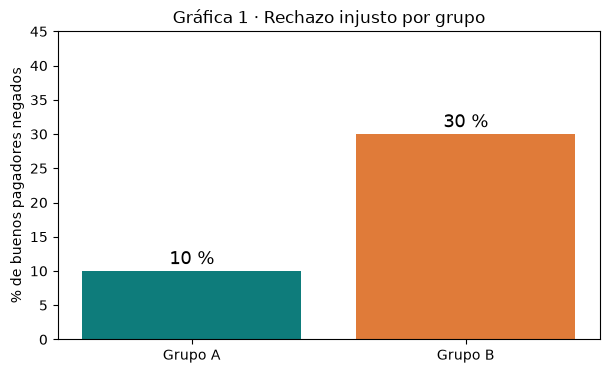

In [13]:
plt.figure(figsize=(7, 4))
barras = plt.bar(["Grupo A", "Grupo B"], [rechazo_A, rechazo_B], color=["#0e7c7b", "#e07b39"])
for b, v in zip(barras, [rechazo_A, rechazo_B]):
    plt.text(b.get_x() + b.get_width() / 2, v + 1, f"{v:.0f} %", ha="center", fontsize=13)
plt.ylim(0, 45)
plt.ylabel("% de buenos pagadores negados")
plt.title("Gráfica 1 · Rechazo injusto por grupo")
plt.show()

## Paso 13 · ¿Y si se borra la columna del grupo?

Una idea que se le ocurre a casi todo el mundo: «si el modelo no ve el grupo, no puede discriminar». Por eso muchos bancos no le dan esa columna al modelo.

El problema es que **otras columnas pueden delatar el grupo**. Supongamos que el modelo sí conoce el **barrio** de cada persona, y que el grupo B vive sobre todo en los barrios 4 y 5. Ejecute la celda: cuenta en qué barrios vive cada grupo.

In [14]:
barrio = [1, 2, 1, 3, 2, 1, 2, 4, 1, 2, 3, 1,     # grupo A
          5, 4, 4, 5, 3, 5, 4, 5, 4, 5, 4, 3]     # grupo B

for el_grupo in ["A", "B"]:
    en_barrios_4_y_5 = 0
    for g, b in zip(grupo, barrio):
        if g == el_grupo and b >= 4:
            en_barrios_4_y_5 = en_barrios_4_y_5 + 1
    print("Grupo", el_grupo, "→ viven en los barrios 4 y 5:", en_barrios_4_y_5, "de 12")

Grupo A → viven en los barrios 4 y 5: 1 de 12
Grupo B → viven en los barrios 4 y 5: 10 de 12


Del grupo A, solo **1 de 12** vive en los barrios 4 y 5; del grupo B, **10 de 12**. Si el modelo aprendió de decisiones pasadas en las que al barrio 4 y 5 se le negaba más, va a seguir negándole más al grupo B **aunque nunca vea la columna del grupo**: el barrio hace de **variable sustituta** (en inglés, *proxy*).

Por eso borrar la columna no basta. Lo que sí funciona es lo que usted acaba de hacer: **medir los errores por grupo**, encontrar la columna sustituta y revisar los datos con los que se entrenó el modelo.

## Resumen de lo que aprendió en Python

| Instrucción | Para qué sirvió |
|---|---|
| `variable = valor` | guardar un número o un texto con nombre |
| `[a, b, c]` | guardar muchos valores en una lista |
| `len`, `sum` | contar y sumar una lista |
| `if` / `else`, `and`, `or` | decidir si una persona cumple una condición |
| `for … in zip(…)` | revisar a cada persona con sus tres datos |
| contador `x = x + 1` | contar cuántas cumplen |
| `def … return` | escribir la cuenta una vez y usarla para cada grupo |
| `plt.bar` | dibujar la comparación |

---
# PARTE E · Taller para entregar

**Individual. 5 puntos. Se entrega en Moodle hasta el viernes 30 de octubre de 2026 a las 23:59.**

Ahora el caso es otro. Una empresa usa un modelo de IA para **filtrar hojas de vida**: el modelo decide qué candidatos pasan a entrevista. Lo probamos con **20 candidatos inventados**: 10 mujeres y 10 hombres. De cada candidato sabemos si **cumplía** el perfil del cargo y si el modelo lo **pasó** a entrevista o lo **descartó**.

Ejecute la celda para crear los datos del taller. **No cambie esta celda**: todos trabajan con los mismos datos.

In [15]:
# Datos del taller: NO los cambie
sexo = ["M"] * 10 + ["H"] * 10      # M = mujer, H = hombre

cumple = ["sí", "sí", "sí", "sí", "sí", "sí", "sí", "sí", "no", "no",    # mujeres
          "sí", "sí", "sí", "sí", "sí", "sí", "sí", "sí", "no", "no"]    # hombres

modelo = ["entrevista", "descartado", "entrevista", "descartado", "entrevista",
          "descartado", "entrevista", "descartado", "descartado", "descartado",   # mujeres
          "entrevista", "entrevista", "entrevista", "entrevista", "descartado",
          "entrevista", "entrevista", "entrevista", "descartado", "entrevista"]   # hombres

pausas_laborales = [1, 2, 0, 2, 0, 3, 1, 2, 0, 1,     # mujeres
                    0, 0, 1, 0, 2, 0, 0, 0, 1, 0]     # hombres

pd.DataFrame({"candidato": range(1, 21), "sexo": sexo, "cumple el perfil": cumple,
              "decisión del modelo": modelo, "pausas laborales (años)": pausas_laborales})

,candidato,sexo,cumple el perfil,decisión del modelo,pausas laborales (años)
0,1,M,sí,entrevista,1
1,2,M,sí,descartado,2
2,3,M,sí,entrevista,0
3,4,M,sí,descartado,2
4,5,M,sí,entrevista,0
5,6,M,sí,descartado,3
6,7,M,sí,entrevista,1
7,8,M,sí,descartado,2
8,9,M,no,descartado,0
9,10,M,no,descartado,1


## Antes de empezar: leer la tabla

Antes de calcular nada, conviene mirar la tabla con calma. Son 20 candidatos: del 1 al 10 son mujeres y del 11 al 20 son hombres. En cada grupo, **8 cumplían el perfil y 2 no**.

La pregunta del taller es la misma de la parte C: **¿el modelo trata igual a las personas que cumplen, sin importar su sexo?** Para responderla hay que contar, grupo por grupo, a quién descartó el modelo.

Los cinco puntos van en este orden:

| Punto | Qué se calcula | Para qué sirve |
|---|---|---|
| 1 | Suma y promedio de las pausas laborales | Ver si las pausas se reparten igual entre mujeres y hombres |
| 2 | La exactitud general | El número que vería alguien que no audita |
| 3 | El descarte injusto por grupo | La prueba del auditor |
| 4 | La gráfica | Mostrar la diferencia de un vistazo |
| 5 | De dónde viene el sesgo | Explicar la causa y proponer qué hacer |

---
## Punto 1 · Python básico: suma y promedio (1,0)

### La cuenta a mano

Las pausas de las **mujeres** son los primeros 10 valores de la lista: `1, 2, 0, 2, 0, 3, 1, 2, 0, 1`.

- Suma: 1 + 2 + 0 + 2 + 0 + 3 + 1 + 2 + 0 + 1 = **12**
- Promedio: 12 ÷ 10 = **1,2 años**

Las pausas de los **hombres** son los últimos 10 valores: `0, 0, 1, 0, 2, 0, 0, 0, 1, 0`.

- Suma: 0 + 0 + 1 + 0 + 2 + 0 + 0 + 0 + 1 + 0 = **4**
- Promedio: 4 ÷ 10 = **0,4 años**

### El código

Cada `None` se reemplaza por la instrucción del **paso 3**: `sum(lista)` suma y `sum(lista) / len(lista)` saca el promedio. `pausas_laborales[0:10]` toma los elementos de la posición 0 a la 9 (las mujeres) y `[10:20]` los de la 10 a la 19 (los hombres).

In [16]:
mujeres = pausas_laborales[0:10]
hombres = pausas_laborales[10:20]

suma_mujeres = sum(mujeres)
promedio_mujeres = sum(mujeres) / len(mujeres)
suma_hombres = sum(hombres)
promedio_hombres = sum(hombres) / len(hombres)

print("Mujeres → suma:", suma_mujeres, "| promedio:", promedio_mujeres)
print("Hombres → suma:", suma_hombres, "| promedio:", promedio_hombres)

Mujeres → suma: 12 | promedio: 1.2
Hombres → suma: 4 | promedio: 0.4


**Respuesta (punto 1):**

- Mujeres: suma = **12** · promedio = 12 ÷ 10 = **1,2 años**
- Hombres: suma = **4** · promedio = 4 ÷ 10 = **0,4 años**

Python da lo mismo que la cuenta a mano. Guarde este dato, porque es la clave del punto 5: **las mujeres tienen, en promedio, el triple de años de pausa laboral que los hombres** (1,2 ÷ 0,4 = 3).

---
## Punto 2 · La exactitud general (1,0)

### La cuenta a mano

El modelo **acierta** en dos casos: pasa a entrevista a alguien que cumple, o descarta a alguien que no cumple. Recorremos la tabla candidato por candidato:

| Candidato | Cumple | Modelo | ¿Acierta? |
|---|---|---|---|
| 1 (M) | sí | entrevista | ✅ |
| 2 (M) | sí | descartado | ❌ |
| 3 (M) | sí | entrevista | ✅ |
| 4 (M) | sí | descartado | ❌ |
| 5 (M) | sí | entrevista | ✅ |
| 6 (M) | sí | descartado | ❌ |
| 7 (M) | sí | entrevista | ✅ |
| 8 (M) | sí | descartado | ❌ |
| 9 (M) | no | descartado | ✅ |
| 10 (M) | no | descartado | ✅ |
| 11 a 14 (H) | sí | entrevista | ✅ ✅ ✅ ✅ |
| 15 (H) | sí | descartado | ❌ |
| 16 a 18 (H) | sí | entrevista | ✅ ✅ ✅ |
| 19 (H) | no | descartado | ✅ |
| 20 (H) | no | entrevista | ❌ |

Mujeres: 6 aciertos. Hombres: 8 aciertos. Total: **14 de 20**.

Exactitud general = 14 ÷ 20 × 100 = **70 %**.

### El código

Es el `if` del **paso 8** con los nombres de este caso: `pagaria` → `cumple`, `decision` → `modelo`, `"aprobado"` → `"entrevista"` y `"negado"` → `"descartado"`. Cada vez que se cumple la condición, el contador `aciertos` suma 1.

In [17]:
aciertos = 0
for c, m in zip(cumple, modelo):
    if (c == "sí" and m == "entrevista") or (c == "no" and m == "descartado"):
        aciertos = aciertos + 1

print("Aciertos:", aciertos, "de", len(modelo))
print("Exactitud general:", round(aciertos / len(modelo) * 100, 1), "%")

Aciertos: 14 de 20
Exactitud general: 70.0 %


**Respuesta (punto 2):**

1. Aciertos contados a mano: **14 de 20** → exactitud = 14 ÷ 20 × 100 = **70 %**.
2. Python da lo mismo: 14 de 20, 70 %.
3. ¿El modelo es bueno? **Con este número solo no se puede saber.** Un 70 % parece aceptable (acierta 7 de cada 10), pero la exactitud general es un promedio de los dos grupos y puede esconder que el modelo se equivoca mucho más con uno de ellos. Antes de decir si es bueno hay que medir los errores **por grupo**, que es justo el punto 3.

> Error común: responder «sí, es bueno porque acierta el 70 %». Es exactamente el error de la sesión de contenido: mirar solo la exactitud general.

---
## Punto 3 · El descarte injusto por grupo (1,0)

### La pregunta del auditor

> **Entre los candidatos que sí cumplían el perfil, ¿a qué porcentaje descartó el modelo en cada grupo?**

Solo cuentan los que **cumplían**: a quien no cumplía, descartarlo es correcto.

### La cuenta a mano

**Mujeres.** Cumplían las candidatas 1 a 8 (las 9 y 10 no cumplían). De esas 8, el modelo descartó a la **2, la 4, la 6 y la 8**: son **4**.

Descarte injusto de mujeres = 4 ÷ 8 × 100 = **50 %**

**Hombres.** Cumplían los candidatos 11 a 18 (los 19 y 20 no cumplían). De esos 8, el modelo descartó solo al **15**: es **1**.

Descarte injusto de hombres = 1 ÷ 8 × 100 = **12,5 %**

**¿Cuántas veces más?** 50 ÷ 12,5 = **4**. Una mujer que cumple el perfil tiene **cuatro veces más** probabilidad de ser descartada que un hombre que lo cumple.

### El código

La celda ya traía la función, que es la misma del **paso 10**: dos contadores (`cumplen` e `injustos`) que solo se mueven cuando el candidato es del sexo pedido y cumplía. Se ejecuta para **verificar** la cuenta a mano.

In [18]:
def descarte_injusto(el_sexo):
    cumplen = 0
    injustos = 0
    for s, c, m in zip(sexo, cumple, modelo):
        if s == el_sexo and c == "sí":
            cumplen = cumplen + 1
            if m == "descartado":
                injustos = injustos + 1
    return injustos / cumplen * 100

descarte_M = descarte_injusto("M")
descarte_H = descarte_injusto("H")
print("Descarte injusto de mujeres:", round(descarte_M, 1), "%")
print("Descarte injusto de hombres:", round(descarte_H, 1), "%")
print("Las mujeres sufren", round(descarte_M / descarte_H, 1), "veces más descartes injustos")

Descarte injusto de mujeres: 50.0 %
Descarte injusto de hombres: 12.5 %
Las mujeres sufren 4.0 veces más descartes injustos


**Respuesta (punto 3):**

| Grupo | Cumplían | Descartados injustamente | Descarte injusto |
|---|---|---|---|
| Mujeres | 8 | 4 | 4 ÷ 8 = **50 %** |
| Hombres | 8 | 1 | 1 ÷ 8 = **12,5 %** |

Las mujeres sufren **4 veces más** descartes injustos que los hombres (50 ÷ 12,5 = 4).

Compare con el punto 2: el mismo modelo con un 70 % de exactitud general deja por fuera a **la mitad** de las mujeres que cumplían.

### Comprobación extra: la exactitud por grupo

No se pedía, pero confirma lo anterior. Es la función del **paso 11** con los nombres del taller.

In [19]:
def exactitud_sexo(el_sexo):
    total = 0
    aciertos = 0
    for s, c, m in zip(sexo, cumple, modelo):
        if s == el_sexo:
            total = total + 1
            if (c == "sí" and m == "entrevista") or (c == "no" and m == "descartado"):
                aciertos = aciertos + 1
    return aciertos / total * 100

print("Exactitud con mujeres:", round(exactitud_sexo("M"), 1), "%")
print("Exactitud con hombres:", round(exactitud_sexo("H"), 1), "%")

Exactitud con mujeres: 60.0 %
Exactitud con hombres: 80.0 %


Mujeres: 6 de 10 (**60 %**). Hombres: 8 de 10 (**80 %**). El 70 % general es el promedio de los dos y esconde la diferencia.

Un detalle: con los hombres el modelo también se equivoca, pero **al revés**: al candidato 20, que no cumplía, lo pasó a entrevista. Con las mujeres el error siempre es en contra: descarta a quien sí cumplía.

---
## Punto 4 · La gráfica (1,0)

### El código

Dos cambios sobre la celda del taller:

1. `valores = [descarte_M, descarte_H]`: la lista con los dos porcentajes del punto 3, en el mismo orden que los nombres de las barras.
2. Un título que **diga lo que muestra** la gráfica, no solo qué variable tiene.

Además se agregó el número encima de cada barra (como en el paso 12), para que la gerente no tenga que adivinarlo leyendo el eje.

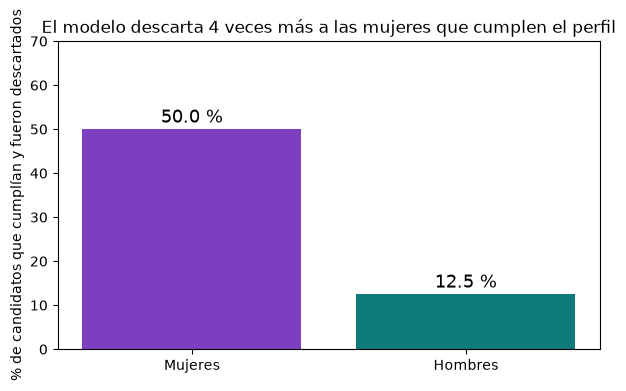

In [20]:
valores = [descarte_M, descarte_H]

plt.figure(figsize=(7, 4))
barras = plt.bar(["Mujeres", "Hombres"], valores, color=["#7b3fbf", "#0e7c7b"])
for b, v in zip(barras, valores):
    plt.text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.1f} %", ha="center", fontsize=13)
plt.ylabel("% de candidatos que cumplían y fueron descartados")
plt.title("El modelo descarta 4 veces más a las mujeres que cumplen el perfil")
plt.ylim(0, 70)
plt.show()

**Respuesta (punto 4):**

Lo que le diría a la gerente:

1. «De cada dos mujeres que cumplen el perfil, el programa descarta a una; de cada ocho hombres que lo cumplen, descarta a uno.»
2. «Eso significa que estamos dejando por fuera a buenas candidatas solo por ser mujeres, y el 70 % de aciertos que muestra el proveedor no deja ver ese problema.»

Fíjese en que las dos frases no usan palabras como «exactitud», «modelo» o «sesgo»: hablan de personas y de proporciones que cualquiera entiende.

---
## Punto 5 · ¿De dónde viene el sesgo? (1,0)

### 1. Por qué las pausas delatan el sexo

Con el punto 1: las mujeres tienen en promedio **1,2 años** de pausa laboral y los hombres **0,4**, el triple. Y si se miran solo las 4 mujeres descartadas injustamente (candidatas 2, 4, 6 y 8), **todas tienen 2 o 3 años de pausa**.

La celda de abajo lo comprueba: recorre a los candidatos que cumplían y muestra las pausas de los que fueron descartados y de los que pasaron.

In [21]:
for el_sexo, nombre in [("M", "Mujeres"), ("H", "Hombres")]:
    pausas_descartados = []
    pausas_pasaron = []
    for s, c, m, p in zip(sexo, cumple, modelo, pausas_laborales):
        if s == el_sexo and c == "sí":
            if m == "descartado":
                pausas_descartados.append(p)
            else:
                pausas_pasaron.append(p)
    print(nombre, "que cumplían → descartados, pausas:", pausas_descartados,
          "| pasaron, pausas:", pausas_pasaron)

Mujeres que cumplían → descartados, pausas: [2, 2, 3, 2] | pasaron, pausas: [1, 0, 0, 1]
Hombres que cumplían → descartados, pausas: [2] | pasaron, pausas: [0, 0, 1, 0, 0, 0, 0]


El patrón es claro: **los candidatos que cumplían y fueron descartados son justo los que tienen 2 o más años de pausa** (las cuatro mujeres con 2, 2, 3 y 2, y el hombre 15 con 2). Quienes pasaron tienen 0 o 1 año.

Entonces el modelo no necesita ver la columna del sexo: le basta con castigar las pausas largas. Como las pausas largas son mucho más frecuentes en las mujeres (por ejemplo, por licencias de maternidad o por cuidar a otras personas), castigar las pausas **es lo mismo que castigar a las mujeres**. Las pausas funcionan como **variable sustituta** del sexo, igual que el barrio en el paso 13.

Y la prueba de que no es solo «culpa de las pausas»: el único hombre con 2 años de pausa también fue descartado. El modelo trata igual a todos los que tienen pausas largas, pero como casi todos son mujeres, el efecto cae sobre ellas.

### 2. La fuente del sesgo

Aparecen dos fuentes de la sesión de contenido:

- **Datos del pasado.** Si el modelo aprendió de las contrataciones que la empresa hizo antes, y antes se contrataba sobre todo a personas sin pausas (casi todos hombres), el modelo copió esa costumbre.
- **Medir la cosa equivocada.** Las pausas laborales no miden si la persona puede hacer el trabajo; miden si su vida laboral fue continua. El perfil del cargo es lo que importa, y el modelo usa un dato que no tiene que ver con él.

### 3. Una acción concreta

Antes de dejar que la empresa use el modelo:

- **Medir el descarte injusto por grupo**, como en el punto 3, con todos los candidatos reales del último año, y no aprobar el modelo mientras la diferencia entre grupos sea grande.
- **Revisar o quitar la columna `pausas_laborales`** y volver a medir: si la diferencia baja, era la variable sustituta.
- Mientras tanto, que **una persona revise los descartes** de candidatos que cumplen el perfil antes de que queden por fuera.

Con una sola de estas acciones, bien explicada, el punto está completo.

---
## Resumen de la solución

| Punto | Resultado |
|---|---|
| 1 | Mujeres: suma 12, promedio 1,2 años. Hombres: suma 4, promedio 0,4 años |
| 2 | 14 aciertos de 20 = **70 %**. Con ese número solo no se sabe si el modelo es bueno |
| 3 | Descarte injusto: mujeres 4 de 8 = **50 %**; hombres 1 de 8 = **12,5 %**. Cuatro veces más |
| 4 | `valores = [descarte_M, descarte_H]` y un título que dice lo que muestra |
| 5 | Las pausas son variable sustituta del sexo; fuentes: datos del pasado y medir la cosa equivocada; acción: medir por grupo, quitar la columna sustituta, revisión humana |

## Resumen en tres ideas

1. **La exactitud general puede esconder el sesgo.** Un 70 % que se ve aceptable puede ser 80 % para un grupo y 60 % para otro.
2. **Para ver el sesgo hay que contar los errores por grupo**: entre quienes cumplían, ¿a qué porcentaje de cada grupo le fue mal? Con un `for`, un `if` y un contador basta.
3. **Borrar la columna del grupo no basta**: otras columnas (el barrio, las pausas laborales) pueden delatarlo. Hay que medir siempre.